In [ ]:
# Goal: Predicting population

In [1]:
# Step 1: import the Libraries

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
# Step 2: Load the dataset

import pandas as pd
df = pd.read_csv("population_data.csv")
df.head()

,id,Country (or dependency),Population 2025,Yearly Change,Net Change,Density (P/Km²),Land Area (Km²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
0,1,India,1463865525,0.89%,12929734,492,2973190,"−495,753",1.94,28.8,37.1%,17.78%
1,2,China,1416096094,−0.23%,"−3,225,184",151,9388211,"−268,126",1.02,40.1,67.5%,17.20%
2,3,United States,347275807,0.54%,1849236,38,9147420,1230663,1.62,38.5,82.8%,4.22%
3,4,Indonesia,285721236,0.79%,2233305,158,1811570,"−39,509",2.10,30.4,59.6%,3.47%
4,5,Pakistan,255219554,1.57%,3950390,331,770880,"−1,235,336",3.50,20.6,34.4%,3.10%


In [5]:
# Step 3: EDA

print(df.shape)

(233, 12)


In [6]:
print(df.head())

   id Country (or dependency)  Population 2025 Yearly Change  Net Change  \
0   1                   India       1463865525         0.89%    12929734   
1   2                   China       1416096094        −0.23%  −3,225,184   
2   3           United States        347275807         0.54%     1849236   
3   4               Indonesia        285721236         0.79%     2233305   
4   5                Pakistan        255219554         1.57%     3950390   

   Density (P/Km²)  Land Area (Km²) Migrants (net)  Fert. Rate  Median Age  \
0              492          2973190       −495,753        1.94        28.8   
1              151          9388211       −268,126        1.02        40.1   
2               38          9147420        1230663        1.62        38.5   
3              158          1811570        −39,509        2.10        30.4   
4              331           770880     −1,235,336        3.50        20.6   

  Urban Pop % World Share  
0       37.1%      17.78%  
1       67.5%     

In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 233 entries, 0 to 232
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       233 non-null    int64  
 1   Country (or dependency)  233 non-null    object 
 2   Population 2025          233 non-null    int64  
 3   Yearly Change            233 non-null    object 
 4   Net Change               233 non-null    object 
 5   Density (P/Km²)          233 non-null    int64  
 6   Land Area (Km²)          233 non-null    int64  
 7   Migrants (net)           233 non-null    object 
 8   Fert. Rate               233 non-null    float64
 9   Median Age               233 non-null    float64
 10  Urban Pop %              210 non-null    object 
 11  World Share              233 non-null    object 
dtypes: float64(2), int64(4), object(6)
memory usage: 22.0+ KB
None


In [8]:
print(df.describe())

               id  Population 2025  Density (P/Km²)  Land Area (Km²)  \
count  233.000000     2.330000e+02       233.000000     2.330000e+02   
mean   117.000000     3.532080e+07       487.673820     5.583427e+05   
std     67.405489     1.391905e+08      2412.937646     1.694270e+06   
min      1.000000     5.010000e+02         0.000000     0.000000e+00   
25%     59.000000     4.663300e+05        38.000000     2.830000e+03   
50%    117.000000     5.731206e+06        98.000000     8.220000e+04   
75%    175.000000     2.407458e+07       256.000000     4.103400e+05   
max    233.000000     1.463866e+09     25732.000000     1.637687e+07   

       Fert. Rate  Median Age  
count  233.000000  233.000000  
mean     2.306094   31.896996  
std      1.134316    9.860936  
min      0.690000   14.500000  
25%      1.470000   22.900000  
50%      1.940000   32.800000  
75%      2.950000   39.800000  
max      5.940000   57.400000  


In [9]:
print(df.isna().sum())

id                          0
Country (or dependency)     0
Population 2025             0
Yearly Change               0
Net Change                  0
Density (P/Km²)             0
Land Area (Km²)             0
Migrants (net)              0
Fert. Rate                  0
Median Age                  0
Urban Pop %                23
World Share                 0
dtype: int64


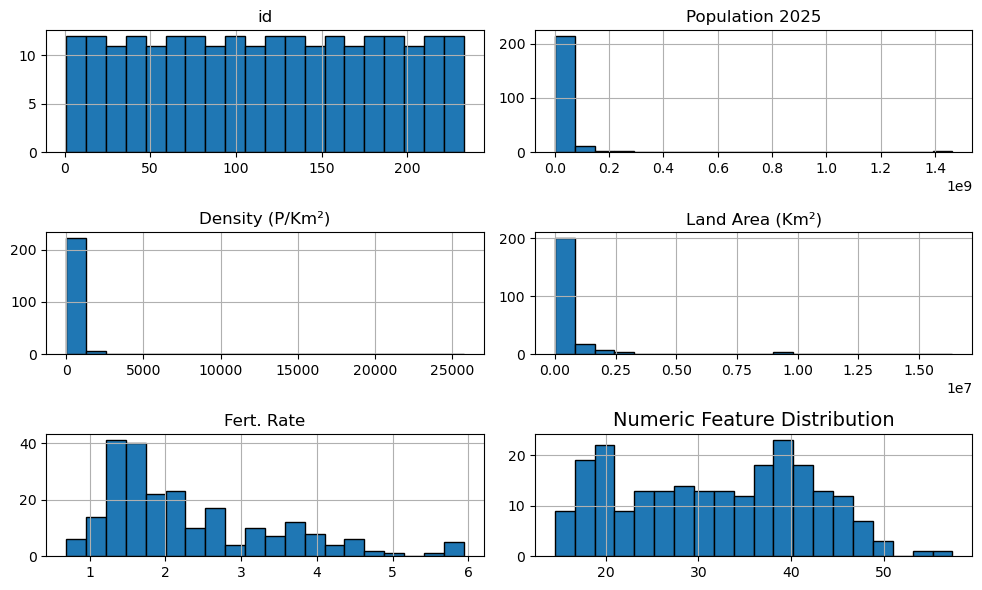

In [16]:
# EDA Visualizations

numeric_cols = df.select_dtypes(include='number').columns

# histogram shows all the numeric columns
df[numeric_cols].hist(figsize=(10,6), bins=20, edgecolor='black')
plt.title("Numeric Feature Distribution", fontsize=14)
plt.tight_layout()
plt.show()


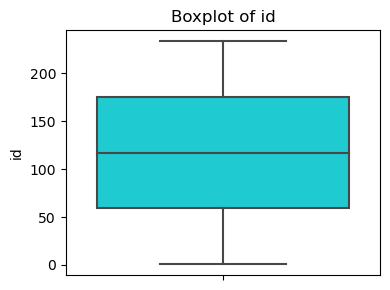

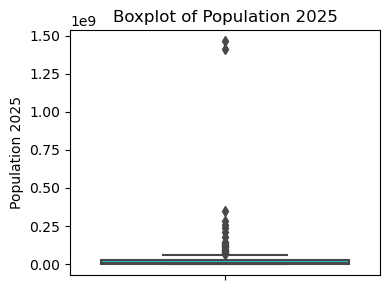

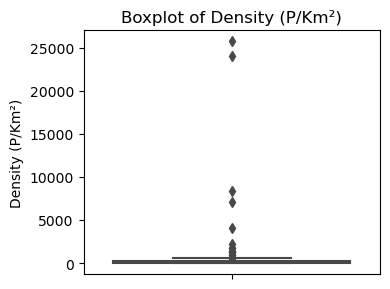

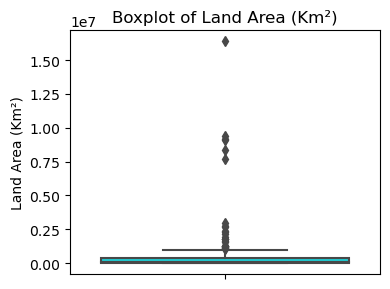

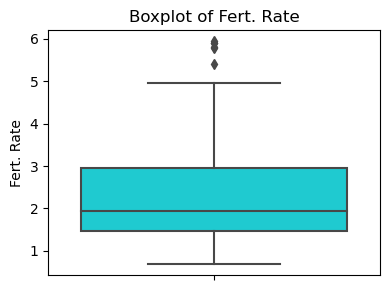

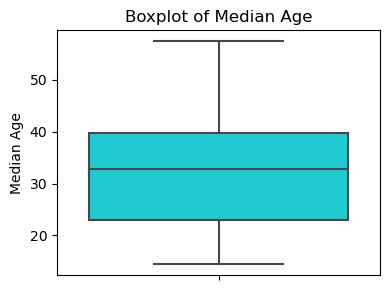

In [18]:
# Box Plot

import seaborn as sns

for col in numeric_cols:
    plt.figure(figsize=(4,3))
    sns.boxplot(y=df[col], color="#02e6ed")
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show


In [24]:
# Step 4: Handling missing values but we don't have any

# Step 5: Handling outliers but we don't have any

# Step 6: Train / Test Split; separating features (x) and target (y)
feature_col = "Population 2025"
target_col = "Population 2025"

x = df[[feature_col]]
y = df[[target_col]]

# Split into train / test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"\nTrain size: {x_train.shape[0]} rows | test size: {x_test.shape[0]} rows")



Train size: 186 rows | test size: 47 rows


In [44]:
# Preprocessing

# identify numeric column to scale (just for one feature)
numeric_feature = [feature_col]

# ColumnTransformer to apply StandardScaler to numeric columns

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_feature)
    ],
    remainder="drop"
)

# Final preprocessing --> Linear Regression

linreg = Pipeline(steps=[
    ("prep", preprocess),
    ("model", LinearRegression())
])
    

In [45]:
# Linear Regression

linreg.fit(x_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Population 2025'])])),
                ('model', LinearRegression())])

In [36]:
# Predicitions on test set
y_pred = linreg.predict(x_test)

# Compute the metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R2 : {r2:,.3f}") 

# Model Evaluation

MAE : 0.00
RMSE : 0.00
R2 : 1.000


Text(0.5, 1.0, 'Linear Regression: Actual vs Predicted Population')

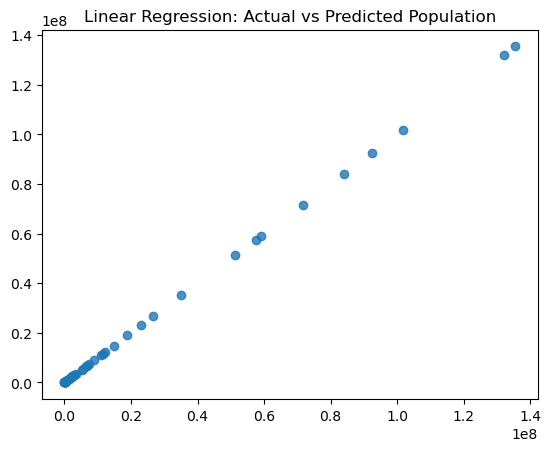

In [41]:
# Plot Model Evaluation

# predicted vs actual

plt.figure()
plt.scatter(y_test, y_pred, alpha=0.8)
plt.title("Linear Regression: Actual vs Predicted Population")

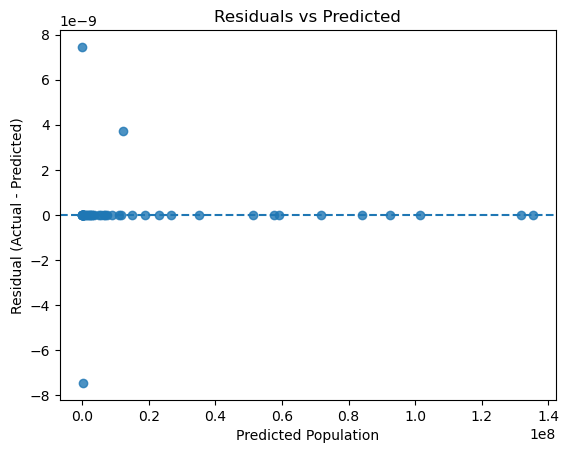

In [40]:
# Residuals plot (residual = acutal - predicted)

residuals = y_test - y_pred

plt.figure()
plt.scatter(y_pred, residuals, alpha=0.8)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted")
plt.xlabel("Predicted Population")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()
